# Photons in Semiconductors

This follows the arc of Saleh & Teich's chapter: how many carriers are there, how
do they absorb and emit light, and how do you detect the photons that come out.
Each step is derived or checked two ways.

| Part | Physics | Math / computing idea |
|---|---|---|
| 1 | carrier densities $n$, $p$ | **improper integrals**: SymPy exactly, `quad`, and a change of variables |
| 2 | intrinsic density, doping, Fermi level | root-finding on charge neutrality |
| 3 | absorption edge, LED spectrum, laser gain | SymPy derivative for the LED peak; the Bernard–Duraffourg inequality |
| 4 | photodetection | **statistics**: photons are Poisson, so shot noise is $2qIB$ |
| 5 | beat frequency and coherent WDM | **parallel** torch simulation (CUDA when available), demultiplexing by FFT |

Module: [`dgs/photons_in_semiconductors.py`](../dgs/photons_in_semiconductors.py). It
reuses `quantum_statistics.fermi_dirac` and `transimpedance_amplifier.responsivity`.

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math

from dgs.photons_in_semiconductors import (
    MATERIALS, K_B_EV, effective_density_cm3, boltzmann_limit_symbolic, fermi_dirac_half,
    fermi_dirac_half_mapped, electron_density, intrinsic_density, fermi_level,
    led_spectrum, led_peak_symbolic, led_fwhm_over_kT, gain_spectrum, bernard_duraffourg_symbolic,
    photon_counts, beat_photocurrent, coherent_wdm_batch,
)
from dgs.transimpedance_amplifier import responsivity
for name, m in MATERIALS.items():
    print(f"{name:5s} Eg = {m['Eg']:.3f} eV ({'direct' if m['direct'] else 'indirect'}),  "
          f"cutoff λ = 1.2398/Eg = {1.2398/m['Eg']*1000:.0f} nm")

Si    Eg = 1.120 eV (indirect),  cutoff λ = 1.2398/Eg = 1107 nm
GaAs  Eg = 1.420 eV (direct),  cutoff λ = 1.2398/Eg = 873 nm
InP   Eg = 1.344 eV (direct),  cutoff λ = 1.2398/Eg = 922 nm


# 1. Carrier density is an improper integral

The electron density counts the available states times the probability that each
is occupied, summed up to infinite energy:

$$n = \int_{E_c}^{\infty}\rho_c(E)\,f(E)\,dE,\qquad \rho_c \propto \sqrt{E - E_c},\quad f = \frac{1}{1 + e^{(E-E_F)/kT}}$$

With $x = (E - E_c)/kT$ and $\eta = (E_F - E_c)/kT$, this becomes

$$n = N_c\,F_{1/2}(\eta),\qquad F_{1/2}(\eta) = \frac{2}{\sqrt\pi}\int_0^\infty \frac{\sqrt{x}}{1 + e^{x-\eta}}\,dx,
\qquad N_c = 2\Big(\frac{2\pi m_e kT}{h^2}\Big)^{3/2}$$

**This integral has no elementary closed form.** In the non-degenerate limit
$\eta \ll 0$, the 1 in the denominator can be dropped, and the integral becomes a
Gamma function that SymPy evaluates exactly:

<IPython.core.display.Math object>

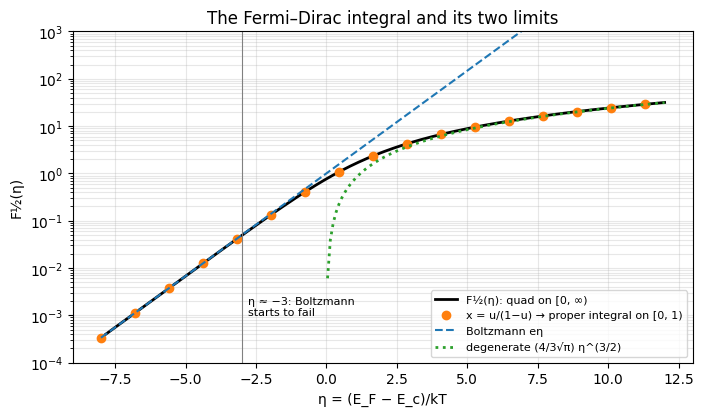

η = -5:  F½ = 0.006722,  Boltzmann/exact = 1.002
η = -3:  F½ = 0.048934,  Boltzmann/exact = 1.017
η = +0:  F½ = 0.765147,  Boltzmann/exact = 1.307
η = +3:  F½ = 4.487547,  Boltzmann/exact = 4.476


In [2]:
display(Math(r"\frac{2}{\sqrt\pi}\int_0^\infty \sqrt{x}\,e^{-(x-\eta)}dx = " + sp.latex(boltzmann_limit_symbolic())))
eta = np.linspace(-8, 12, 200)
F = fermi_dirac_half(eta)
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.semilogy(eta, F, "k", lw=2, label="F½(η): quad on [0, ∞)")
ax.semilogy(eta[::12], fermi_dirac_half_mapped(eta[::12]), "o", color="C1", label="x = u/(1−u) → proper integral on [0, 1)")
ax.semilogy(eta, np.exp(eta), "C0--", label="Boltzmann eη")
ax.semilogy(eta[eta > 0], 4/(3*np.sqrt(np.pi))*eta[eta > 0]**1.5, "C2:", lw=2, label="degenerate (4/3√π) η^(3/2)")
ax.axvline(-3, color="0.5", lw=0.8); ax.text(-2.8, 1e-3, "η ≈ −3: Boltzmann\nstarts to fail", fontsize=8)
ax.set(xlabel="η = (E_F − E_c)/kT", ylabel="F½(η)", ylim=(1e-4, 1e3), title="The Fermi–Dirac integral and its two limits")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both"); plt.show()
for e_ in (-5, -3, 0, 3):
    print(f"η = {e_:+d}:  F½ = {float(fermi_dirac_half(e_)):.6f},  Boltzmann/exact = {np.exp(e_)/float(fermi_dirac_half(e_)):.3f}")

**Improper-integral technique.** The substitution $x = u/(1-u)$ maps
$[0, \infty) \to [0, 1)$ with $dx = du/(1-u)^2$. A plain midpoint rule on the finite
interval then matches `quad` to about 7 digits. When you hit an infinite limit, the
first move is usually a change of variables that makes it finite.

**Physics.** The Boltzmann approximation overestimates $n$ once $E_F$ gets within a
few $kT$ of the band edge, and it's off by a factor of 4.5 by $\eta = 3$. Heavily
doped regions and laser active regions are *degenerate*, so they need the full
integral.

# 2. Intrinsic density, doping, and the Fermi level

With no doping, $n = p = n_i = \sqrt{N_cN_v}\,e^{-E_g/2kT}$, which is
exponentially sensitive to the band gap and temperature. Doping sets $E_F$ through
**charge neutrality** $n + N_a = p + N_d$, solved here with the full Fermi–Dirac
integrals, and the mass-action law $np = n_i^2$ follows.

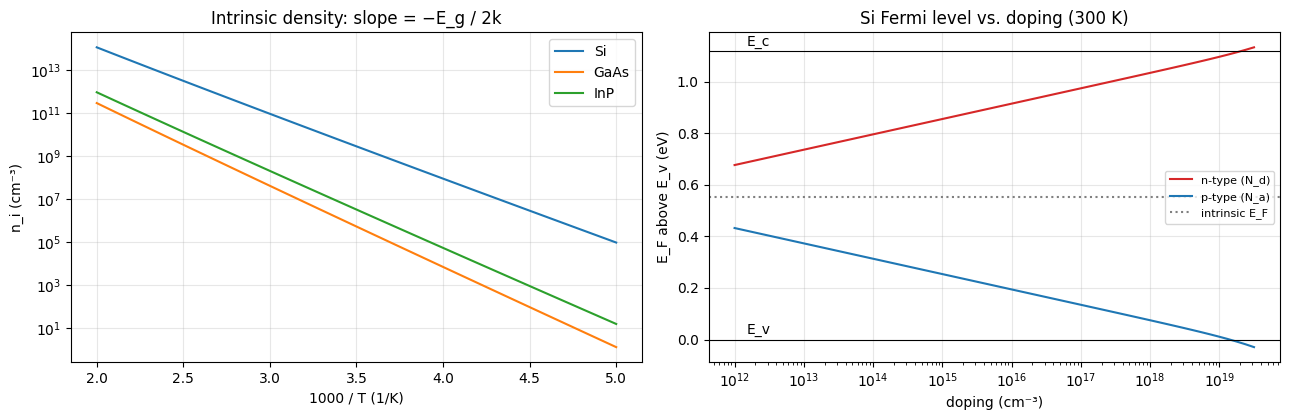

Si, N_d = 1e16: n = 1.0000e+16, p = 7.8846e+03, n·p = 7.8846e+19, n_i² = 7.8856e+19
intrinsic n_i: Si 8.88e+09, GaAs 2.25e+06 cm⁻³


In [3]:
T = np.linspace(200, 500, 100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for name, col in (("Si", "C0"), ("GaAs", "C1"), ("InP", "C2")):
    axes[0].semilogy(1000/T, [intrinsic_density(name, tt) for tt in T], col, label=name)
axes[0].set(xlabel="1000 / T (1/K)", ylabel="n_i (cm⁻³)", title="Intrinsic density: slope = −E_g / 2k")
axes[0].legend(); axes[0].grid(alpha=0.3, which="both")

Nd = np.logspace(12, 19.5, 60)
EgSi = MATERIALS["Si"]["Eg"]
EFn = [fermi_level(Nd=x, material="Si")["E_F"] for x in Nd]
EFp = [fermi_level(Na=x, material="Si")["E_F"] for x in Nd]
axes[1].semilogx(Nd, EFn, "C3", label="n-type (N_d)"); axes[1].semilogx(Nd, EFp, "C0", label="p-type (N_a)")
axes[1].axhline(EgSi, color="k", lw=0.8); axes[1].axhline(0, color="k", lw=0.8)
axes[1].axhline(fermi_level(material="Si")["E_F"], color="0.5", ls=":", label="intrinsic E_F")
axes[1].text(1.5e12, EgSi + 0.02, "E_c"); axes[1].text(1.5e12, 0.02, "E_v")
axes[1].set(xlabel="doping (cm⁻³)", ylabel="E_F above E_v (eV)", title="Si Fermi level vs. doping (300 K)")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

r = fermi_level(Nd=1e16, material="Si")
print(f"Si, N_d = 1e16: n = {r['n']:.4e}, p = {r['p']:.4e}, n·p = {r['n']*r['p']:.4e}, n_i² = {intrinsic_density('Si')**2:.4e}")
print(f"intrinsic n_i: Si {intrinsic_density('Si'):.2e}, GaAs {intrinsic_density('GaAs'):.2e} cm⁻³")

At very high doping, $E_F$ goes *into* the band, which is the degenerate regime from
Part 1. A Boltzmann-only model would get this wrong, but the full $F_{1/2}$ handles
it without special cases.

# 3. Light at the band edge: absorption, LEDs, and gain

In a direct-gap semiconductor, a photon of energy $h\nu$ connects a valence state
and a conduction state at the same $k$. The number of such pairs (the **joint
density of states**) grows as $\sqrt{h\nu - E_g}$.

**LED.** Thermal occupation $e^{-(h\nu-E_g)/kT}$ times $\sqrt{h\nu - E_g}$ gives the
spontaneous-emission spectrum. SymPy finds its peak:

<IPython.core.display.Math object>

FWHM = 1.795 kT  (= 46.4 meV at 300 K)


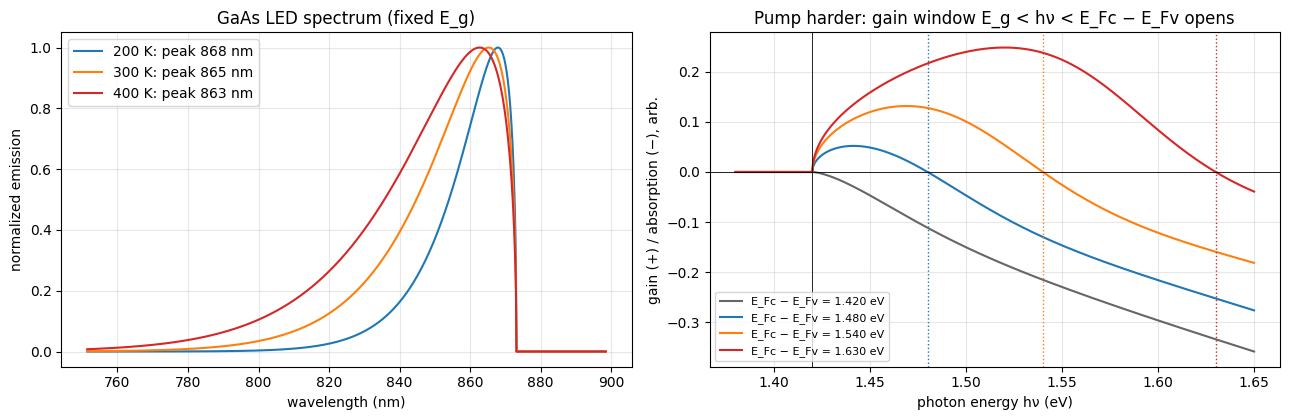

In [4]:
display(Math(r"\frac{d}{dx}\left[\sqrt{x}\,e^{-x/kT}\right] = 0 \;\Rightarrow\; x = " + sp.latex(led_peak_symbolic())))
print(f"FWHM = {led_fwhm_over_kT():.3f} kT  (= {led_fwhm_over_kT()*K_B_EV*300*1000:.1f} meV at 300 K)")
EgG = MATERIALS["GaAs"]["Eg"]
hv = np.linspace(1.38, 1.65, 1000)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for T_, col in ((200, "C0"), (300, "C1"), (400, "C3")):
    S = led_spectrum(hv, EgG, T_)
    axes[0].plot(1239.84/hv, S/S.max(), col, label=f"{T_} K: peak {1239.84/hv[np.argmax(S)]:.0f} nm")
axes[0].set(xlabel="wavelength (nm)", ylabel="normalized emission", title="GaAs LED spectrum (fixed E_g)")
axes[0].legend(); axes[0].grid(alpha=0.3)

for dF, col in ((0.0, "0.4"), (0.04, "C0"), (0.08, "C1"), (0.14, "C3")):
    EFc, EFv = EgG + dF, -dF/2
    g = gain_spectrum(hv, EFc, EFv)
    axes[1].plot(hv, g, col, label=f"E_Fc − E_Fv = {EFc - EFv:.3f} eV")
    if EFc - EFv > EgG:
        axes[1].axvline(EFc - EFv, color=col, ls=":", lw=1)
axes[1].axhline(0, color="k", lw=0.6); axes[1].axvline(EgG, color="k", lw=0.6)
axes[1].set(xlabel="photon energy hν (eV)", ylabel="gain (+) / absorption (−), arb.",
            title="Pump harder: gain window E_g < hν < E_Fc − E_Fv opens")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Why lasers need inversion (Bernard–Duraffourg).** Net gain is proportional to
$f_c(E_2) - f_v(E_1)$. SymPy puts the difference over a common denominator. The
denominator is always positive, so the sign comes entirely from the numerator:

In [5]:
num = bernard_duraffourg_symbolic()
display(Math(r"\operatorname{sign}[f_c(E_2) - f_v(E_1)] = \operatorname{sign}\left[" + sp.latex(num) + r"\right]"))
print("positive  ⇔  E1 + F_c > E2 + F_v  ⇔  hν = E2 − E1 < F_c − F_v")

<IPython.core.display.Math object>

positive  ⇔  E1 + F_c > E2 + F_v  ⇔  hν = E2 − E1 < F_c − F_v


So you get gain only for photons with $E_g < h\nu < E_{Fc} - E_{Fv}$. The
quasi-Fermi-level separation has to exceed the band gap, which means injecting
enough current to *invert* the band edge. The dotted lines in the right-hand plot
mark where gain turns back into absorption.

# 4. Detection: photons are Poisson

A photodiode with quantum efficiency $\eta$ turns photons into electrons with
responsivity $\mathcal R = \eta q\lambda/hc$ (A/W). Above the cutoff wavelength
$hc/E_g$, photons can't cross the gap. Photon arrivals from a laser are random and
independent, so the counts are **Poisson**: variance equals mean. That's where shot
noise $\sigma_i^2 = 2qIB$ comes from.

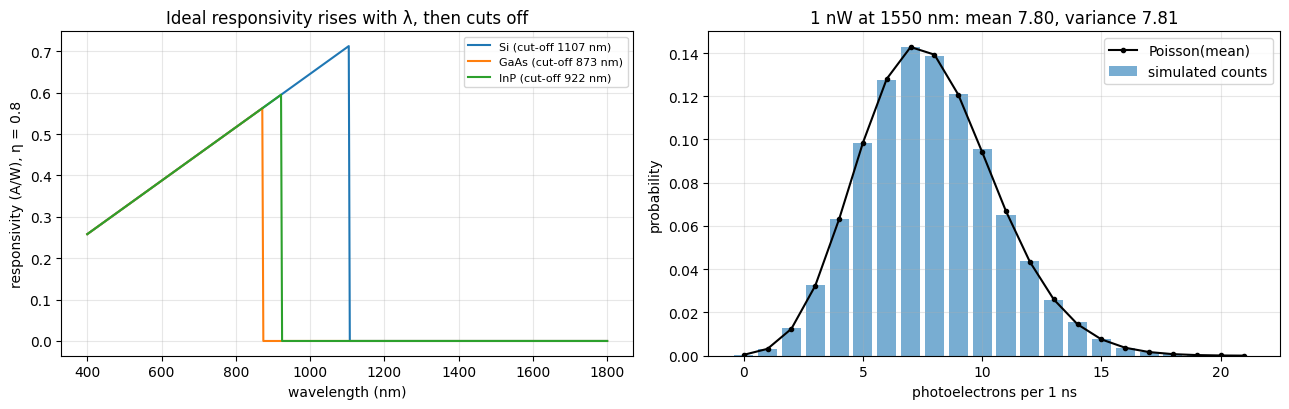

variance / mean = 1.0004  (Poisson → 1)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
lam = np.linspace(400, 1800, 500)
for name, col in (("Si", "C0"), ("GaAs", "C1"), ("InP", "C2")):
    cut = 1239.84/MATERIALS[name]["Eg"]
    axes[0].plot(lam, np.where(lam < cut, [responsivity(l, 0.8) for l in lam], 0), col, label=f"{name} (cut-off {cut:.0f} nm)")
axes[0].set(xlabel="wavelength (nm)", ylabel="responsivity (A/W), η = 0.8", title="Ideal responsivity rises with λ, then cuts off")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

c, mean = photon_counts(1e-9, 1550, 1e-9, n=100000)
k = np.arange(0, c.max() + 1)
from math import factorial
pois = np.array([np.exp(-mean)*mean**kk/factorial(int(kk)) for kk in k])
axes[1].bar(k, np.bincount(c)/len(c), color="C0", alpha=0.6, label="simulated counts")
axes[1].plot(k, pois, "ko-", ms=3, label="Poisson(mean)")
axes[1].set(xlabel="photoelectrons per 1 ns", ylabel="probability",
            title=f"1 nW at 1550 nm: mean {mean:.2f}, variance {c.var():.2f}")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"variance / mean = {c.var()/c.mean():.4f}  (Poisson → 1)")

# 5. Beat frequency and coherent WDM, simulated in parallel

A photodiode measures $|E|^2$. Shine two lasers on it and the cross term survives:

$$i(t) = \mathcal R\big[P_1 + P_2 + 2\sqrt{P_1P_2}\cos(2\pi\,\Delta f\,t)\big]$$

The current **beats** at the difference frequency $\Delta f$. Two optical frequencies
around 193 THz produce an electrical tone at a few GHz that ordinary electronics can
measure. That's heterodyne detection (see also `heterodyne_detection.py`).

**Coherent WDM.** Put several data channels near one strong local oscillator (LO).
Each channel beats with the LO at its own intermediate frequency, so one FFT
separates them. Every trial is independent, which makes the simulation
**embarrassingly parallel**: torch runs all trials as one batched tensor, on CUDA
if a GPU is visible.

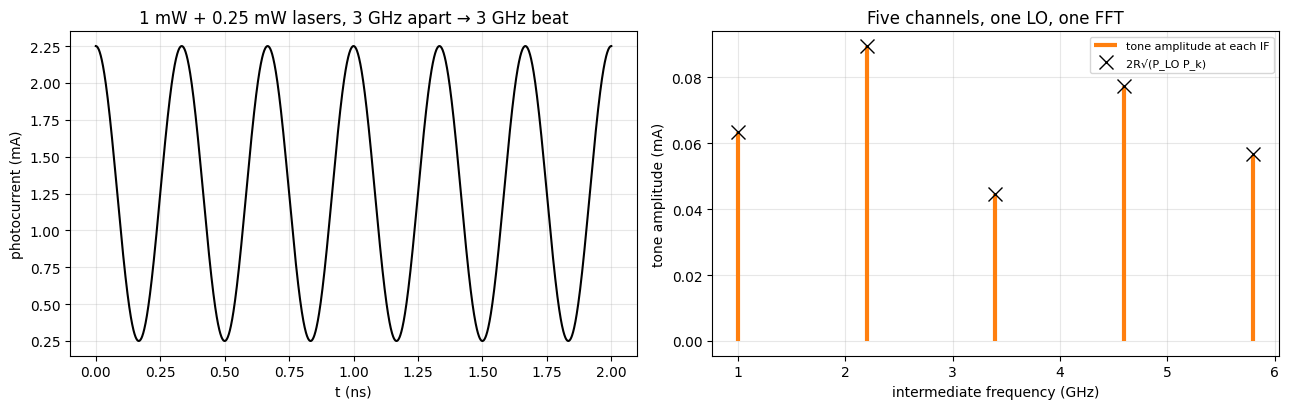

device used: cuda
 channel  true P (µW)  recovered mean  std over 256 trials
       0        1.000          1.0000              0.00125
       1        2.000          2.0001              0.00191
       2        0.500          0.4999              0.00091
       3        1.500          1.5000              0.00159
       4        0.800          0.8000              0.00119


In [7]:
t = np.linspace(0, 2e-9, 2000)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(1e9*t, 1e3*beat_photocurrent(1e-3, 0.25e-3, 3e9, t), "k")
axes[0].set(xlabel="t (ns)", ylabel="photocurrent (mA)", title="1 mW + 0.25 mW lasers, 3 GHz apart → 3 GHz beat")
axes[0].grid(alpha=0.3)

P_ch = np.array([1.0, 2.0, 0.5, 1.5, 0.8]) * 1e-6
f_if = np.array([1.0, 2.2, 3.4, 4.6, 5.8]) * 1e9
r = coherent_wdm_batch(P_ch, f_if, P_lo=1e-3, trials=256, seed=1)
import torch
# one trial's tones for display
rr =coherent_wdm_batch(P_ch, f_if, P_lo=1e-3, trials=1, seed=2, device="cpu")
axes[1].vlines(rr["f_snapped"]/1e9, 0, 1e3*rr["tone_measured"][0], color="C1", lw=3, label="tone amplitude at each IF")
axes[1].plot(rr["f_snapped"]/1e9, 1e3*rr["tone_expected"], "kx", ms=10, label="2R√(P_LO P_k)")
axes[1].set(xlabel="intermediate frequency (GHz)", ylabel="tone amplitude (mA)", title="Five channels, one LO, one FFT")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"device used: {r['device']}")
print(f"{'channel':>8s} {'true P (µW)':>12s} {'recovered mean':>15s} {'std over 256 trials':>20s}")
for k_, (p, m_, s_) in enumerate(zip(P_ch, r["recovered"].mean(0), r["recovered"].std(0))):
    print(f"{k_:8d} {1e6*p:12.3f} {1e6*m_:15.4f} {1e6*s_:20.5f}")

In [8]:
# Timing: batched trials on CPU vs. CUDA (if present)
for dev in (["cpu", "cuda"] if torch.cuda.is_available() else ["cpu"]):
    coherent_wdm_batch(P_ch, f_if, trials=8, device=dev)        # warm-up
    t0 = time.perf_counter()
    coherent_wdm_batch(P_ch, f_if, n=8192, trials=2048, device=dev)
    if dev == "cuda": torch.cuda.synchronize()
    print(f"{dev:5s}: 2048 trials × 8192 samples in {time.perf_counter() - t0:.3f} s")
if not torch.cuda.is_available():
    print("(no CUDA device visible to this kernel — same code runs on GPU unchanged)")

cpu  : 2048 trials × 8192 samples in 0.917 s


cuda : 2048 trials × 8192 samples in 0.414 s


**Why use a strong LO?** The beat amplitude $2\mathcal R\sqrt{P_\text{LO}P_k}$ grows
with the LO power. Receiver thermal noise (here a 50 Ω load) is fixed, so a stronger
LO lifts weak channels above it. Shot noise grows as $\sqrt{P_\text{LO}}$ too, so past
some point the SNR stops improving. That plateau is the **shot-noise limit**, the
best a classical receiver can do.

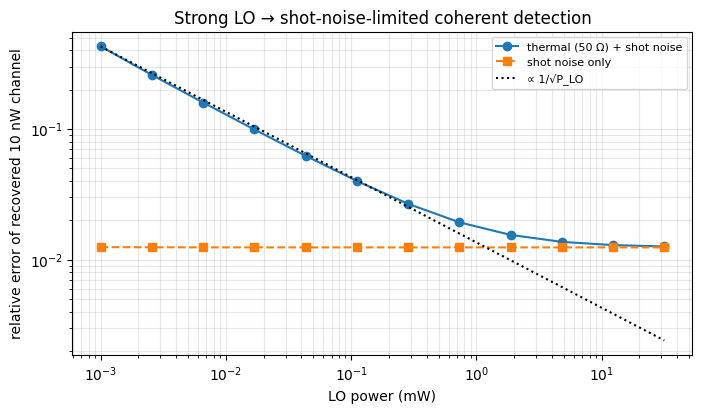

In [9]:
P_los = np.logspace(-6, -1.5, 12)
std_th = [coherent_wdm_batch([1e-8], [2e9], P_lo=p, trials=200, R_load=50.0, seed=7)["recovered"].std()/1e-8 for p in P_los]
std_sh = [coherent_wdm_batch([1e-8], [2e9], P_lo=p, trials=200, seed=7)["recovered"].std()/1e-8 for p in P_los]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.loglog(1e3*P_los, std_th, "o-", label="thermal (50 Ω) + shot noise")
ax.loglog(1e3*P_los, std_sh, "s--", label="shot noise only")
ax.loglog(1e3*P_los, std_th[0]*np.sqrt(P_los[0]/P_los), "k:", label="∝ 1/√P_LO")
ax.set(xlabel="LO power (mW)", ylabel="relative error of recovered 10 nW channel",
       title="Strong LO → shot-noise-limited coherent detection")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both"); plt.show()

# Summary

| result | how it was checked |
|---|---|
| $n = N_cF_{1/2}(\eta)$, Boltzmann limit $= N_ce^\eta$ | SymPy exact Gamma integral; `quad` = mapped midpoint to 1e-7 |
| $n_i$: Si ≈ 9e9, GaAs ≈ 2e6 cm⁻³; $np = n_i^2$ | charge-neutrality root find |
| LED peak $E_g + kT/2$, FWHM ≈ 1.8 kT | SymPy derivative + numerical half-max |
| gain only for $E_g < h\nu < E_{Fc} - E_{Fv}$ | SymPy sign of $f_c - f_v$ + numerical gain spectrum |
| photon counts Poisson, var/mean = 1 | simulation |
| coherent WDM recovers each channel; strong LO → shot-noise limit | batched torch simulation vs. $2\mathcal R\sqrt{P_\text{LO}P_k}$ |

## Exercises
1. Add the temperature dependence of $E_g$ (Varshni: $E_g(T) = E_g(0) - \alpha T^2/(T+\beta)$) and redo the LED spectra. Which way does the peak shift as the chip heats?
2. Find the injected carrier density $n = p$ at which GaAs reaches transparency at the band edge ($E_{Fc} - E_{Fv} = E_g$). Hint: `fermi_level`-style root finding on each band.
3. Replace the 50 Ω load with a transimpedance amplifier from `transimpedance_amplifier.py`. Where does the shot-noise limit start now?
4. Why does Si appear in the responsivity plot even though it's an *indirect*-gap material? (What does that do to its absorption length?)
5. Add channel–channel beat terms ($2\sqrt{P_jP_k}$) to the WDM simulation. When do they start to matter?